In [1]:
# Imports and settings (Task 3-3 CIFAR-10)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.datasets import cifar10

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:
# Load and preprocess CIFAR-10 (normalize + labels)

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# normalize to [0,1]
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# y is shape (n,1) -> flatten to (n,)
y_train = y_train.flatten()
y_test  = y_test.flatten()

print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test :", x_test.shape,  "y_test :", y_test.shape)
print("min/max:", x_train.min(), x_train.max())

class_names = ["airplane","automobile","bird","cat","deer",
               "dog","frog","horse","ship","truck"]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 7457s 44us/step
x_train: (50000, 32, 32, 3) y_train: (50000,)
x_test : (10000, 32, 32, 3) y_test : (10000,)
min/max: 0.0 1.0


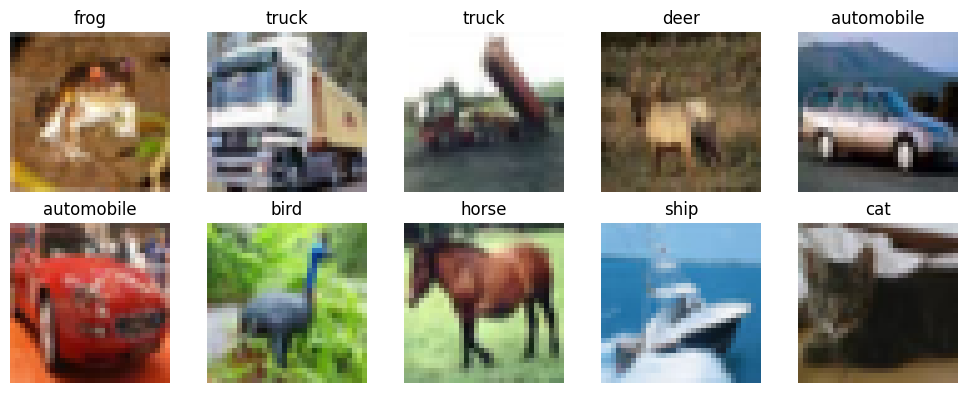

In [3]:
# Show CIFAR-10 sample images (sanity check)

plt.figure(figsize=(10, 4))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# Build CIFAR-10 Baseline CNN

def build_cifar10_cnn():
    model = Sequential([
        layers.Conv2D(32, (3,3), activation="relu", input_shape=(32,32,3)),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation="relu"),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation="relu"),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=Adam(),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

cifar_cnn = build_cifar10_cnn()
cifar_cnn.summary()


c:\Users\hasan\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Train CIFAR-10 CNN (epochs=10) + evaluate

history_cifar = cifar_cnn.fit(
    x_train, y_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=1
)

test_loss_cifar, test_acc_cifar = cifar_cnn.evaluate(x_test, y_test, verbose=0)
print("CIFAR-10 Test Loss:", test_loss_cifar)
print("CIFAR-10 Test Accuracy:", test_acc_cifar)


Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 25s 59ms/step - accuracy: 0.3892 - loss: 1.6740 - val_accuracy: 0.5045 - val_loss: 1.3744
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - accuracy: 0.5305 - loss: 1.3058 - val_accuracy: 0.5792 - val_loss: 1.1858
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 52ms/step - accuracy: 0.5928 - loss: 1.1533 - val_accuracy: 0.6166 - val_loss: 1.0869
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.6291 - loss: 1.0552 - val_accuracy: 0.6427 - val_loss: 1.0179
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - accuracy: 0.6558 - loss: 0.9815 - val_accuracy: 0.6557 - val_loss: 0.9830
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - accuracy: 0.6755 - loss: 0.9252 - val_accuracy: 0.6542 - val_loss: 1.0019
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - accuracy: 0.6939 - loss: 0.8795 - val_accuracy: 0.6624 - val_loss: 0.9813
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.7080 - loss: 0.8371 - 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step


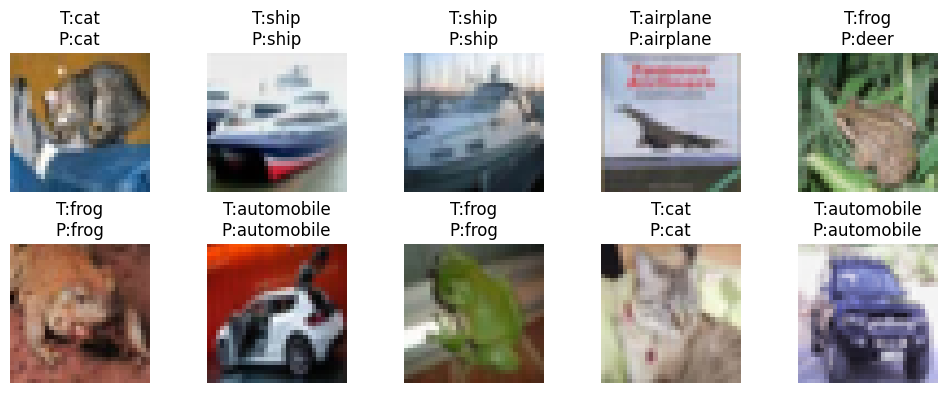

In [6]:
# Predict and visualize CIFAR-10 outputs (10 samples)

pred_probs = cifar_cnn.predict(x_test[:10])
pred_labels = np.argmax(pred_probs, axis=1)

plt.figure(figsize=(10, 4))
for i in range(10):
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    true_name = class_names[y_test[i]]
    pred_name = class_names[pred_labels[i]]
    plt.title(f"T:{true_name}\nP:{pred_name}")
    plt.axis("off")
plt.tight_layout()
plt.show()
